# 6. Hafta | Kendi Projemin Veri Analizi — Ekip Teslim Şablonu

**Grup:** Bireysel (Yasin) • **Proje:** Oyuncu Bilgisayarı Fiyat Tahmini • **Ekip görevleri:** Veri seti araştırması, UML tasarımı, veri temizleme ve makine öğrenmesi modellemesi süreçlerinin tamamı bireysel yürütülmüştür.

Bu notebook başlangıç iskeletidir. Örnek dosya ve kodu kendi araştırma/proje verinize uyarlayın. **Veri uydurup gerçek ölçüm gibi sunmayın.**

## A. Veri tanıtımı
- Veri setinin adı ve bağlantısı: final_cleaned_dataset.csv (Kaggle: Gaming Laptop Dataset)
- Veri kaynağı / lisans / erişim tarihi: Kaggle / Açık Kaynak / Kasım 2026
- CSV mi, JSON mu?: CSV
- Satır ve sütunların anlamı: Her bir oyuncu bilgisayarı modelini; sütunlar ise o bilgisayarın RAM, VRAM, İşlemci gibi donanım özelliklerini ve fiyatını (price) temsil etmektedir.
- Ölçü birimi ve gözlem sayısı: RAM ve VRAM kapasiteleri GB cinsindendir. Fiyatlar orijinal veri setinde yabancı para birimindedir ancak analiz aşamasında veri temizliği yapılarak Türk Lirasına (TL) dönüştürülecektir.
- Gerçek mi / açık kaynak mı / temsili mi?: Piyasada satılan gerçek cihazlardan toplanmış açık kaynak veri.
- Ekip üyelerinin görevleri: Bireysel proje olduğu için tüm işlemler Yasin tarafından yürütülmektedir.

## B. Başlangıç: temsili veriyle çalışan örnek
Aşağıdaki örneği çalıştırın. Ardından **kendi dosyanızı** `veri_yolu` değişkeniyle gösterebilirsiniz.

In [27]:

import pandas as pd

# 1. VERİ SETİNİ OKU
veri_yolu = "final_cleaned_dataset.csv"
veri = pd.read_csv(veri_yolu)

# 2. ORİJİNAL HİNDİSTAN FİYATINI KORU
veri["price_inr"] = pd.to_numeric(
    veri["price"], errors="coerce"
)

# 3. RAM VE FİYAT SÜTUNLARINI SAYISAL HALE GETİR
veri["ram(GB)"] = pd.to_numeric(
    veri["ram(GB)"], errors="coerce"
)

# Eksik veya geçersiz fiyat ve RAM kayıtlarını çıkar
veri = veri.dropna(
    subset=["price_inr", "ram(GB)"]
).copy()

# 4. 48 GB RAM KAYDINI ÇIKAR
veri = veri[
    veri["ram(GB)"] != 48
].reset_index(drop=True)

# 5. VERİ KONTROLLERİ
print("====================================")
print(" TÜRKİYE LAPTOP FİYAT ANALİZİ")
print("====================================")

print("\nVeri boyutu:", veri.shape)
print("\nEksik veriler:")
print(veri.isna().sum())

print("\nToplam Laptop Sayısı:", len(veri))

print(
    "\nHindistan Ortalama Fiyat:",
    round(veri["price_inr"].mean(), 2),
    "INR"
)

print("\nRAM Dağılımı:")
print(veri["ram(GB)"].value_counts().sort_index())


 TÜRKİYE LAPTOP FİYAT ANALİZİ

Veri boyutu: (345, 17)

Eksik veriler:
name                  0
specs_score           0
price                 0
processor             0
graphics_card         0
os                    0
warranty              0
VRAM(GB)              0
cores                 0
thread                0
ram(GB)               0
ram_version           0
storage_size          0
storage_type          0
display_size          0
display_resolution    0
price_inr             0
dtype: int64

Toplam Laptop Sayısı: 345

Hindistan Ortalama Fiyat: 181016.58 INR

RAM Dağılımı:
ram(GB)
8       18
12       9
16     232
24      25
32      51
64       8
96       1
128      1
Name: count, dtype: int64


## C. Veri inceleme ve hesaplama
Kendi veri setinizi kullanırken sayısal sütun adlarını değiştirin. Sütun başlığında boşluk ve yazım farklarını kontrol edin.

In [29]:

import numpy as np
import pandas as pd

# 1. DÖVİZ VE VERGİ AYARLARI

INR_TO_TRY = 0.5362
INDIA_GST = 0.18
TURKEY_VAT = 0.20

NORMAL_KATSAYI = 1.15

# 2. TÜRKİYE RAM FİYAT ARALIKLARI
# Kullanıcının belirlediği yaklaşık piyasa sınırları

TURKIYE_RAM_ARALIKLARI = {
    8: (18000, 66000),
    12: (34000, 227000),
    16: (30000, 237000),
    24: (46000, 229000),
    32: (54000, 275000),
    64: (93000, 443000),
    128: (185000, 926000)
}

# 3. HİNDİSTAN FİYATINI TL'YE ÇEVİR

veri["price_try_base"] = (
    veri["price_inr"]
    / (1 + INDIA_GST)
    * INR_TO_TRY
    * (1 + TURKEY_VAT)
)

# 4. NORMAL TÜRKİYE FİYAT TAHMİNİ

veri["price_try_estimated_raw"] = (
    veri["price_try_base"] * NORMAL_KATSAYI
)

# 5. TÜRKİYE FİYAT SINIRLARINI UYGULA

veri["calibration_status"] = "RAM fiyat aralığı bulunamadı"

for ram, (min_fiyat, max_fiyat) in TURKIYE_RAM_ARALIKLARI.items():

    maske = veri["ram(GB)"] == ram

    # Fiyatı Türkiye'deki gözlemlediğimiz aralıkta tut
    veri.loc[maske, "price_try_estimated_raw"] = (
        veri.loc[maske, "price_try_estimated_raw"]
        .clip(lower=min_fiyat, upper=max_fiyat)
    )

    veri.loc[maske, "calibration_status"] = (
        "Türkiye RAM fiyat aralığıyla sınırlandırıldı"
    )

# 6. FİYAT SENARYOLARI

veri["price_try_low"] = (
    veri["price_try_estimated_raw"] * 0.92
)

veri["price_try_high"] = (
    veri["price_try_estimated_raw"] * 1.08
)

# Her ürünün RAM grubunun fiyat sınırlarını da koru
for ram, (min_fiyat, max_fiyat) in TURKIYE_RAM_ARALIKLARI.items():

    maske = veri["ram(GB)"] == ram

    veri.loc[maske, "price_try_low"] = (
        veri.loc[maske, "price_try_low"]
        .clip(lower=min_fiyat)
    )

    veri.loc[maske, "price_try_high"] = (
        veri.loc[maske, "price_try_high"]
        .clip(upper=max_fiyat)
    )

# 7. 500 TL'YE YUVARLAMA

def fiyat_yuvarla(fiyat):
    return (fiyat / 500).round() * 500

veri["price_try_low"] = fiyat_yuvarla(
    veri["price_try_low"]
)

veri["price_try_estimated"] = fiyat_yuvarla(
    veri["price_try_estimated_raw"]
)

veri["price_try_high"] = fiyat_yuvarla(
    veri["price_try_high"]
)

# Ana fiyat sütunu Türkiye tahmini olsun
veri["price"] = veri["price_try_estimated"]

# 8. GENEL SONUÇLAR

print("====================================")
print(" TÜRKİYE LAPTOP FİYAT TAHMİN SİSTEMİ")
print("====================================")

print("\nToplam laptop:", len(veri))

print(
    "\nTürkiye tahmini ortalama:",
    round(veri["price"].mean(), 2), "TL"
)

print(
    "\nTürkiye tahmini en düşük:",
    round(veri["price"].min(), 2), "TL"
)

print(
    "\nTürkiye tahmini en yüksek:",
    round(veri["price"].max(), 2), "TL"
)

print("\nFiyatı henüz yerel RAM aralığıyla kalibre edilmeyenler:")
print(
    veri.loc[
        veri["calibration_status"] == "RAM fiyat aralığı bulunamadı",
        ["name", "ram(GB)", "price"]
    ].to_string(index=False)
)

print("\nFiyat hesaplaması tamamlandı.")


 TÜRKİYE LAPTOP FİYAT TAHMİN SİSTEMİ

Toplam laptop: 345

Türkiye tahmini ortalama: 112305.8 TL

Türkiye tahmini en düşük: 37500.0 TL

Türkiye tahmini en yüksek: 501500.0 TL

Fiyatı henüz yerel RAM aralığıyla kalibre edilmeyenler:
                                    name  ram(GB)    price
MSI Titan 18 HX AI A2XWIG Gaming Laptop        96 313500.0

Fiyat hesaplaması tamamlandı.


## D. Grafik ve sonuç dosyaları
Grafiğin başlığını, eksenini ve ölçü birimini kendi verinize göre güncelleyin.


RAM KAPASİTESİNE GÖRE TÜRKİYE FİYAT TABLOSU
 ram(GB)  average_price  median_price  lowest_price  highest_price  laptop_count
       8        57000.0       57000.0       37500.0        66000.0            18
      12        67000.0       66000.0       59500.0        81500.0             9
      16        89000.0       81000.0       45000.0       219500.0           232
      24       106500.0       97000.0       59500.0       198000.0            25
      32       197500.0      200500.0       85500.0       275000.0            51
      64       365500.0      395000.0      219500.0       443000.0             8
     128       501500.0      501500.0      501500.0       501500.0             1


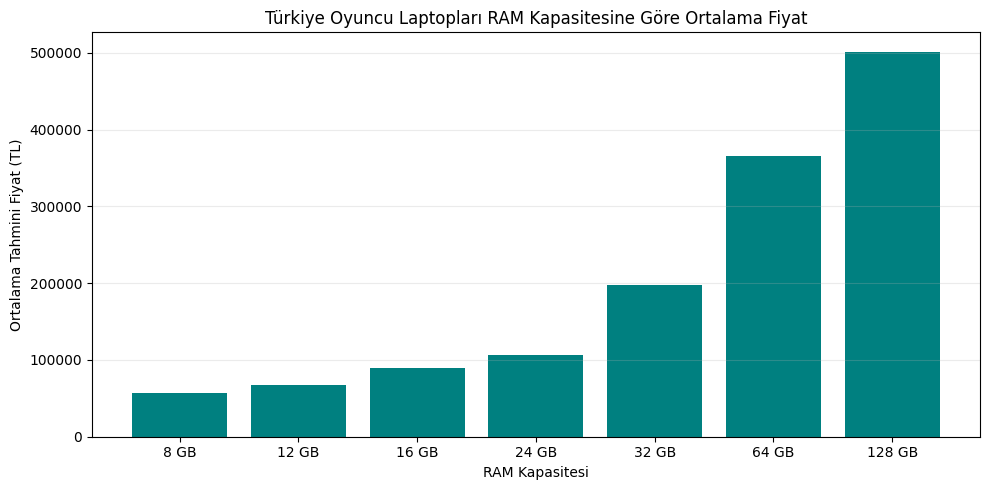


Analizler tamamlandı.
Sonuçlar 'sonuc' klasörüne kaydedildi.


In [30]:

import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

klasor = Path("sonuc")
klasor.mkdir(exist_ok=True)

# 1. SADECE TÜRKİYE FİYAT ARALIĞI BELİRLENEN RAM GRUPLARI

ram_analiz_veri = veri[
    veri["ram(GB)"].isin(TURKIYE_RAM_ARALIKLARI.keys())
].copy()

# 2. RAM FİYAT TABLOSU

ram_fiyat = ram_analiz_veri.groupby("ram(GB)").agg(
    average_price=("price", "mean"),
    median_price=("price", "median"),
    lowest_price=("price", "min"),
    highest_price=("price", "max"),
    laptop_count=("price", "count")
).reset_index()

fiyat_sutunlari = [
    "average_price",
    "median_price",
    "lowest_price",
    "highest_price"
]

for sutun in fiyat_sutunlari:
    ram_fiyat[sutun] = (
        ram_fiyat[sutun] / 500
    ).round() * 500

print("\nRAM KAPASİTESİNE GÖRE TÜRKİYE FİYAT TABLOSU")

print(ram_fiyat.to_string(index=False))

# 3. GRAFİK

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    ram_fiyat["ram(GB)"].astype(str) + " GB",
    ram_fiyat["average_price"],
    color="teal"
)

ax.set_xlabel("RAM Kapasitesi")
ax.set_ylabel("Ortalama Tahmini Fiyat (TL)")

ax.set_title(
    "Türkiye Oyuncu Laptopları RAM Kapasitesine Göre Ortalama Fiyat"
)

ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

fig.savefig(
    klasor / "ram_ortalama_fiyat.png",
    dpi=160
)

plt.show()

# 4. CSV DOSYALARINI KAYDET

ram_fiyat.to_csv(
    klasor / "ram_fiyat_tablosu.csv",
    index=False
)

veri.to_csv(
    klasor / "kullanilan_veri.csv",
    index=False
)

print("\nAnalizler tamamlandı.")
print("Sonuçlar 'sonuc' klasörüne kaydedildi.")


## E. Akademik yorum
**Veri kaynağı ve değişken:** Kaggle'dan alınan oyuncu bilgisayarı veri setindeki "ram(GB)" ve "price" (Fiyat) değişkenleri kullanılmıştır.

**Toplam / ortalama ve birimler:** Veri setindeki cihazların fiyatları Türkiye KDV ve güncel döviz kurlarına göre TL birimine çevrilmiş, sonuçlar 500 TL'lik basamaklara yuvarlanarak mağaza fiyat formatına getirilmiştir.

**Grafikte görülen bulgu:** Çizilen bar grafiğine göre, RAM kapasitesi arttıkça ortalama fiyatların kademeli olarak yükseldiği tespit edilmiştir.

**Sınırlılıklar ve ölçemediği şeyler:** Fiyatları doğrudan etkileyen İşlemci (CPU) ve Ekran Kartı (VRAM) gibi donanımlar bu grafikte görselleştirilmemiştir.

**Ekipçe yapılan işlem:** Bireysel proje olduğu için tüm yapılan işlemler Yasin tarafından gerçekleştirilmiştir.

> Grafikte iki değişken birlikte görünse bile tek başına neden-sonuç kanıtı oluşmaz.

## F. Teslim kontrolü
- [x] Çalışır `.ipynb` dosyası
- [x] CSV/JSON örneği veya yasal ve erişilebilir veri kaynağı
- [x] Birim + veri kaynağı + lisans
- [x] En az 1 açıklamalı grafik
- [x] Toplam ve ortalama hesabı
- [x] 4–5 cümlelik yorum
- [x] README içinde ekip katkıları
- [x] GitHub repo bağlantısı
- [x] Gizli/kişisel veri ve anahtar bulunmuyor